# Práctica dirigida – Solución
**Machine Learning para la Toma de Decisiones · Universidad del Pacífico · 2026**

Este notebook resuelve los dos casos de la práctica dirigida: **Caso 1** (regresión) y **Caso 2** (serie de tiempo). Subir a Colab los archivos `PD_agentes_retiros.csv`, `PD_agentes_nuevos.csv` y `PD_recaudos_trx.csv`.

# Caso 1 – ¿Cuánto efectivo necesitará cada agente?

**Práctica dirigida · Machine Learning para la Toma de Decisiones · Universidad del Pacífico**

**Red AgenteYa** opera una red de agentes corresponsales (bodegas, farmacias, minimarkets) donde los clientes retiran efectivo. Cada mañana, el área de Operaciones decide cuánto efectivo debe tener cada agente con una regla fija: **el promedio de retiros diarios de los últimos 7 días**. Cuando los retiros del día superan ese monto en más de S/ 500, el agente se queda sin efectivo (**faltante**): pierde transacciones y hay que enviar un abastecimiento urgente, con un costo estimado de S/ 40 por caso.

El gerente de Operaciones quiere **reducir a la mitad los días con faltante**. La base `PD_agentes_retiros.csv` contiene 9,000 registros agente-día de julio a setiembre de 2026 (datos simulados).

## 1. Configuración

In [81]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
import lightgbm as lgb
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error, r2_score

warnings.filterwarnings("ignore")
SEED = 42
pd.set_option("display.float_format", "{:.2f}".format)
pd.set_option("display.max_colwidth", None)
AZUL, NARANJA, GRIS, MARINO = "#1570BC", "#E8892B", "#9AA8BF", "#000F5A"

### Parámetros del caso

Como en el caso RapiMenú, todo lo que depende del caso está en la celda siguiente.

In [82]:
# Datos
ARCHIVO = "PD_agentes_retiros.csv"
ARCHIVO_NUEVOS = "PD_agentes_nuevos.csv"
SALIDA_NUEVOS = "PD_prediccion_agentes2.csv"
ID = "id_registro"
OBJETIVO = "monto_retiros"
UNIDAD = "S/"
COLUMNAS_A_EXCLUIR = ["id_registro", "fecha", "id_agente"]      # identificadores y fechas
CATEGORICAS = ["dia_semana", "region", "zona", "tipo_comercio"]

def limpiar(data, es_nuevo=False):
    # Tratamiento de nulos y atípicos (las medianas se calculan con la base de entrenamiento)
    data = data.copy()
    data.loc[data["antiguedad_meses"] > 120, "antiguedad_meses"] = np.nan    # 999 = error de registro
    data["antiguedad_meses"] = data["antiguedad_meses"].fillna(MEDIANAS["antiguedad_meses"])
    data["horario_atencion_h"] = data["horario_atencion_h"].fillna(MEDIANAS["horario_atencion_h"])
    if not es_nuevo:
        data = data[data[OBJETIVO] > 0]                                     # días con el agente cerrado
    return data

def crear_variables(data):
    data = data.copy()
    data["fin_de_semana"] = data["dia_semana"].isin(["Sábado", "Domingo"]).astype(int)
    return data

# Línea base: cómo decide hoy el negocio
NOMBRE_LINEA_BASE = "Regla actual"
def linea_base(data):
    return data["retiros_prom_7d"]

# Indicador de negocio y meta
TOLERANCIA = 500
IND = f"% días con faltante > S/ {TOLERANCIA}"
def indicador(y_real, y_pred):
    return ((y_real - y_pred) > TOLERANCIA).mean() * 100
META_RELATIVA = 0.5

# Valor económico
COSTO_POR_CASO = 40.0          # S/ por faltante (abastecimiento urgente y transacciones perdidas)
NOMBRE_COSTO = "faltantes"
CASOS_POR_MES = 27000          # 900 agentes × 30 días

In [83]:
df = pd.read_csv(ARCHIVO)
print(f"Registros: {len(df):,} | Variables: {df.shape[1]}")
df.head()

Registros: 9,000 | Variables: 15


,id_registro,fecha,id_agente,dia_semana,dia_mes,dia_pago,feriado,region,zona,tipo_comercio,antiguedad_meses,horario_atencion_h,transacciones_prom_7d,retiros_prom_7d,monto_retiros
0,700001,2026-07-01,5505,Miércoles,1,1,0,Oriente,Rural,Farmacia,40.00,10.00,11.10,995.00,1997.00
1,700002,2026-07-01,5010,Miércoles,1,1,0,Sur,Urbana,Bodega,45.00,8.00,10.50,1600.00,1527.00
2,700003,2026-07-01,5002,Miércoles,1,1,0,Norte,Rural,Minimarket,36.00,14.00,16.70,1675.00,3177.00
3,700004,2026-07-01,5429,Miércoles,1,1,0,Lima,Urbana,Librería,28.00,12.00,16.60,2320.00,2436.00
4,700005,2026-07-01,5301,Miércoles,1,1,0,Lima,Urbana,Bodega,48.00,12.00,39.30,4712.00,7327.00


## 2. Pregunta 1 · Revisión de calidad de los datos

Revisamos tipos de datos, valores faltantes, duplicados y valores atípicos.

In [84]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9000 entries, 0 to 8999
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   id_registro            9000 non-null   int64  
 1   fecha                  9000 non-null   object 
 2   id_agente              9000 non-null   int64  
 3   dia_semana             9000 non-null   object 
 4   dia_mes                9000 non-null   int64  
 5   dia_pago               9000 non-null   int64  
 6   feriado                9000 non-null   int64  
 7   region                 9000 non-null   object 
 8   zona                   9000 non-null   object 
 9   tipo_comercio          9000 non-null   object 
 10  antiguedad_meses       8820 non-null   float64
 11  horario_atencion_h     8865 non-null   float64
 12  transacciones_prom_7d  9000 non-null   float64
 13  retiros_prom_7d        9000 non-null   float64
 14  monto_retiros          9000 non-null   float64
dtypes: f

In [85]:
print("Valores faltantes por columna:")
print(df.isnull().sum()[df.isnull().sum() > 0])
print(f"\nRegistros duplicados: {df.duplicated().sum()}")

Valores faltantes por columna:
antiguedad_meses      180
horario_atencion_h    135
dtype: int64

Registros duplicados: 0


In [86]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
id_registro,9000.00,704500.50,2598.22,700001.00,702250.75,704500.50,706750.25,709000.00
id_agente,9000.00,5452.98,259.91,5001.00,5228.00,5452.00,5677.00,5900.00
dia_mes,9000.00,15.81,8.89,1.00,8.00,16.00,24.00,31.00
dia_pago,9000.00,0.25,0.43,0.00,0.00,0.00,0.00,1.00
feriado,9000.00,0.04,0.20,0.00,0.00,0.00,0.00,1.00
antiguedad_meses,8820.00,32.17,33.96,1.00,16.00,32.00,47.00,999.00
horario_atencion_h,8865.00,11.87,2.20,8.00,10.00,12.00,14.00,16.00
transacciones_prom_7d,9000.00,16.06,10.72,1.90,8.60,13.50,20.30,90.70
retiros_prom_7d,9000.00,1874.69,1248.84,232.00,1003.00,1577.50,2361.25,10188.00
monto_retiros,9000.00,1973.81,1573.31,0.00,926.75,1582.00,2540.00,21614.00


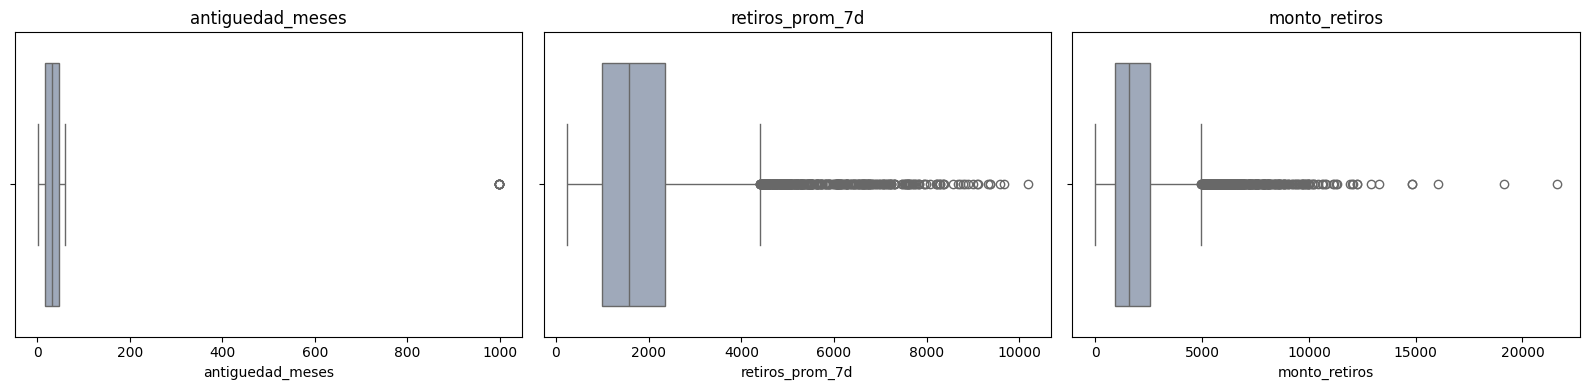

Antigüedad > 120 meses (imposible: la red tiene 5 años): 8
Días con retiros = 0 (agente cerrado): 120
Días con retiros > 3 veces su promedio de 7 días: 45


In [87]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["antiguedad_meses", "retiros_prom_7d", "monto_retiros"]):
    sns.boxplot(x=df[col], ax=ax, color=GRIS)
    ax.set_title(col)
plt.tight_layout()
plt.show()

print("Antigüedad > 120 meses (imposible: la red tiene 5 años):", (df["antiguedad_meses"] > 120).sum())
print("Días con retiros = 0 (agente cerrado):", (df["monto_retiros"] == 0).sum())
print("Días con retiros > 3 veces su promedio de 7 días:", (df["monto_retiros"] > 3 * df["retiros_prom_7d"]).sum())

**Hallazgos de calidad**

- **Nulos:** `antiguedad_meses` (180 registros, 2%) y `horario_atencion_h` (135, 1.5%). No hay duplicados.
- **Atípicos por error de registro:** 8 agentes con antigüedad de 999 meses, lo que es imposible porque la red tiene 5 años.
- **Días con retiros = 0 (120 casos):** corresponden a días en que el agente no abrió. No son días con demanda cero, sino días sin operación. Además, con valores reales en cero el MAPE se indefine, porque divide entre cero.
- **Días con retiros mayores a 3 veces su promedio (45):** son eventos reales (pagos de bonos, campañas), no errores. Se mantienen, porque el modelo debe aprender a convivir con ellos.

In [88]:
MEDIANAS = {"antiguedad_meses": df.loc[df["antiguedad_meses"] <= 120, "antiguedad_meses"].median(),
            "horario_atencion_h": df["horario_atencion_h"].median()}
n_antes = len(df)
df = limpiar(df)
print(f"Registros: {n_antes:,} → {len(df):,} (se eliminan {n_antes - len(df)} días con el agente cerrado)")
print("Nulos restantes:", df.isnull().sum().sum())

Registros: 9,000 → 8,880 (se eliminan 120 días con el agente cerrado)
Nulos restantes: 0


**Tratamiento aplicado:** las antigüedades de 999 se convierten en nulo; los nulos de antigüedad y horario se imputan con la mediana; se eliminan los 120 días con el agente cerrado. Las medianas se calculan con la base de entrenamiento y se reutilizan para el archivo de agentes nuevos.

## 3. Pregunta 2 · Análisis descriptivo

In [89]:
df[OBJETIVO].describe()

,monto_retiros
count,8880.00
mean,2000.48
std,1566.97
min,87.00
25%,949.00
50%,1600.00
75%,2552.00
max,21614.00


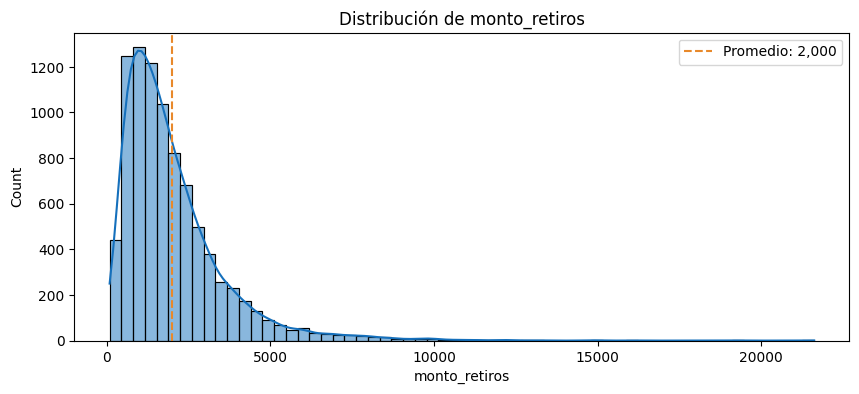

In [90]:
plt.figure(figsize=(10, 4))
sns.histplot(df[OBJETIVO], bins=60, kde=True, color=AZUL)
plt.axvline(df[OBJETIVO].mean(), color=NARANJA, ls="--", label=f"Promedio: {df[OBJETIVO].mean():,.0f}")
plt.title(f"Distribución de {OBJETIVO}")
plt.xlabel(OBJETIVO)
plt.legend()
plt.show()

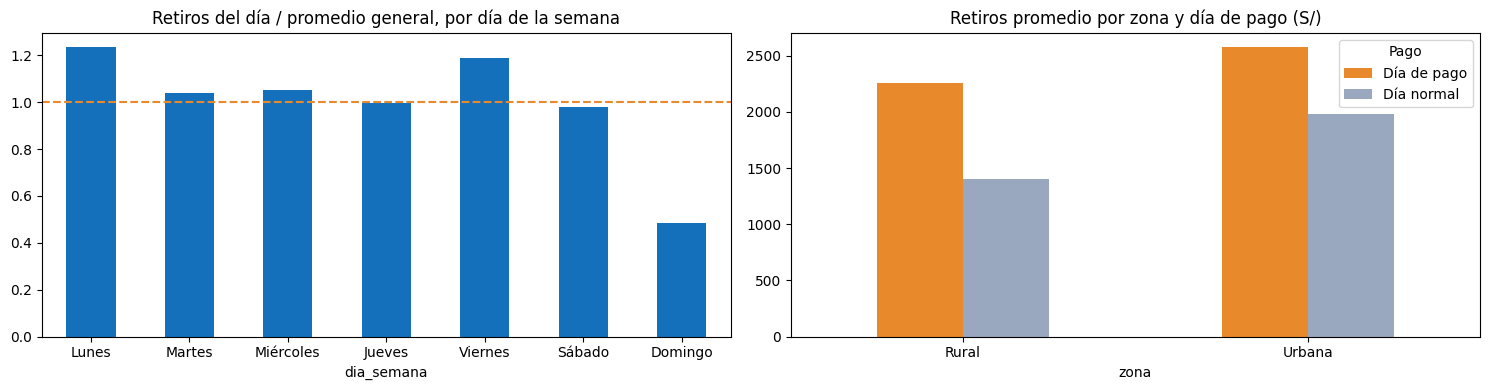

In [91]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
orden = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]
(df.groupby("dia_semana")[OBJETIVO].mean().reindex(orden) / df[OBJETIVO].mean()).plot.bar(ax=axes[0], color=AZUL, rot=0)
axes[0].axhline(1, color=NARANJA, ls="--")
axes[0].set_title("Retiros del día / promedio general, por día de la semana")
df.assign(Pago=np.where(df["dia_pago"] == 1, "Día de pago", "Día normal")).groupby(["zona", "Pago"])[OBJETIVO].mean().unstack().plot.bar(ax=axes[1], color=[NARANJA, GRIS], rot=0)
axes[1].set_title("Retiros promedio por zona y día de pago (S/)")
plt.tight_layout()
plt.show()

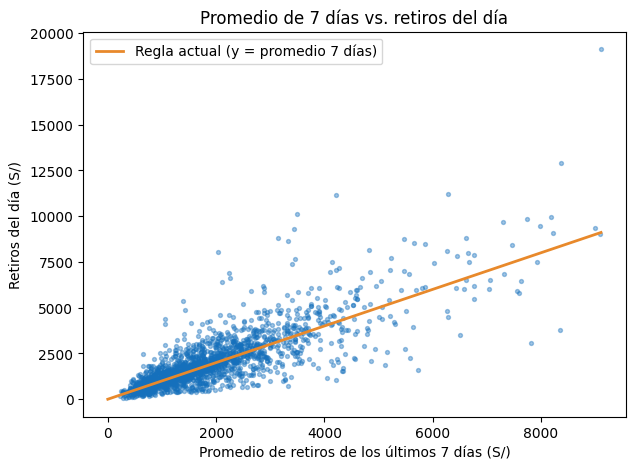

In [92]:
muestra = df.sample(2000, random_state=SEED)
plt.figure(figsize=(7, 5))
plt.scatter(muestra["retiros_prom_7d"], muestra[OBJETIVO], s=8, alpha=0.4, color=AZUL)
x = np.linspace(0, muestra["retiros_prom_7d"].max(), 50)
plt.plot(x, x, color=NARANJA, lw=2, label="Regla actual (y = promedio 7 días)")
plt.xlabel("Promedio de retiros de los últimos 7 días (S/)")
plt.ylabel("Retiros del día (S/)")
plt.title("Promedio de 7 días vs. retiros del día")
plt.legend()
plt.show()

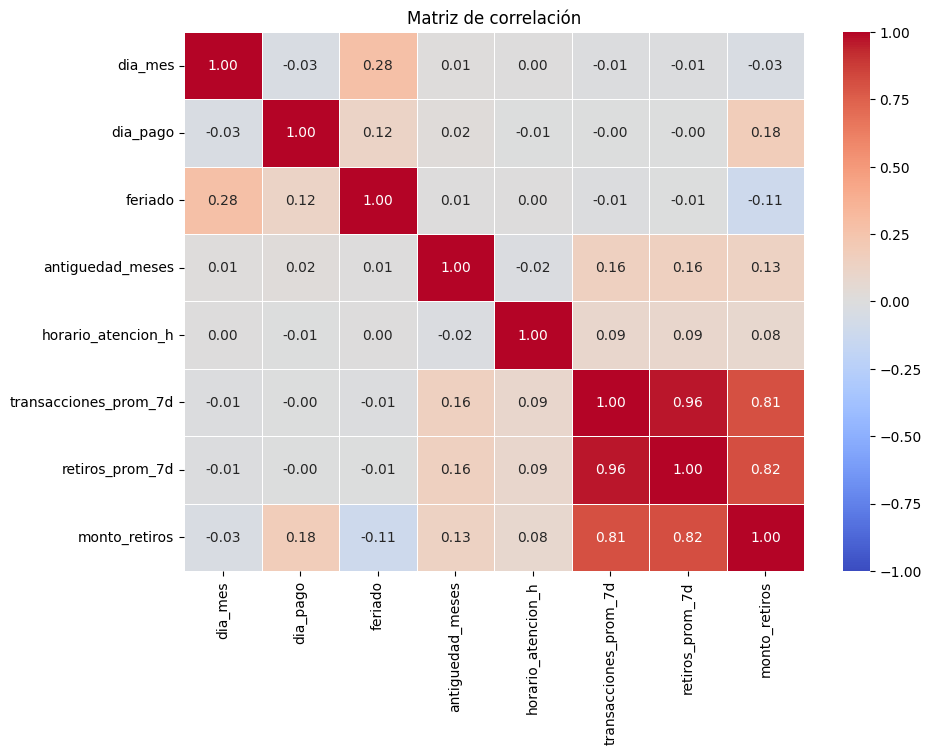

In [93]:
numericas = df.select_dtypes(include=np.number).drop(columns=[x for x in COLUMNAS_A_EXCLUIR if x in df.select_dtypes(include=np.number).columns])
plt.figure(figsize=(10, 7))
sns.heatmap(numericas.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Matriz de correlación")
plt.show()

**Hallazgos relevantes**

1. **El día de la semana cambia mucho los retiros.** El lunes se retira 23% más que el promedio y el viernes 19% más; el domingo, la mitad (0.49 veces el promedio). La regla actual, que usa el promedio de 7 días, no distingue el día.
2. **Los días de pago elevan los retiros, sobre todo en zonas rurales.** En la zona rural, un día de pago tiene en promedio S/ 2,258 de retiros frente a S/ 1,405 en un día normal (+61%); en la zona urbana el aumento es de 30% (S/ 2,576 frente a S/ 1,980). Los feriados tienen 44% menos retiros.
3. El promedio de 7 días está muy correlacionado con los retiros del día (0.82), pero la nube de puntos se abre para los agentes grandes: la regla acierta en promedio, pero se equivoca mucho día a día.

## 4. Preparación de los datos

- Se crean las variables derivadas definidas en los parámetros.
- Se eliminan los identificadores: el modelo memorizaría casos, sin aprender patrones.
- Las variables categóricas se convierten en variables dummy (*one-hot encoding*).
- Se separa 80% para entrenamiento y 20% para prueba.

In [94]:
datos = crear_variables(df)
y = datos[OBJETIVO]
X = datos.drop(columns=COLUMNAS_A_EXCLUIR + [OBJETIVO])
X = pd.get_dummies(X, columns=CATEGORICAS, drop_first=True, dtype=int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=SEED)
print(f"Entrenamiento: {len(X_train):,} | Prueba: {len(X_test):,} | Variables: {X.shape[1]}")

Entrenamiento: 7,104 | Prueba: 1,776 | Variables: 23


## 5. Métricas

| Métrica | Qué responde |
|---|---|
| **MAE** | ¿Cuánto se equivoca en promedio, en soles? |
| **RMSE** | ¿Hay errores grandes? Los castiga más |
| **MAPE** | ¿Cuánto se equivoca en % del valor real? |
| **R²** | ¿Cuánto mejora frente a predecir siempre el promedio? |

Además, la **métrica de negocio**: **% de días con faltante > S/ 500**: días en que los retiros reales superan lo previsto en más de S/ 500 y el agente se queda sin efectivo.

In [95]:
def metricas(y_real, y_pred):
    return {"MAE": mean_absolute_error(y_real, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_real, y_pred)),
            "MAPE (%)": mean_absolute_percentage_error(y_real, y_pred) * 100,
            "R²": r2_score(y_real, y_pred),
            IND: indicador(y_real, y_pred)}

## 6. Pregunta 3 · ¿Qué tan buena es la regla actual?

In [96]:
pred_regla = linea_base(datos.loc[X_test.index])
pd.Series(metricas(y_test, pred_regla), name=NOMBRE_LINEA_BASE).to_frame()

,Regla actual
MAE,573.51
RMSE,952.25
MAPE (%),34.75
R²,0.66
% días con faltante > S/ 500,20.78


In [97]:
ind_regla = indicador(y_test, pred_regla)
META = ind_regla * META_RELATIVA
print(f"Hoy, con la regla actual: {IND} = {ind_regla:.1f}%")
print(f"Meta: reducirlo a la mitad, es decir, a {META:.1f}% o menos.")

Hoy, con la regla actual: % días con faltante > S/ 500 = 20.8%
Meta: reducirlo a la mitad, es decir, a 10.4% o menos.


**Respuesta:** la regla se equivoca en promedio en S/ 574 por agente y día (MAPE de 35%). En el **20.8%** de los días el agente se queda sin efectivo (faltante mayor a S/ 500). Su R² de 0.66 parece alto, pero se debe a que el promedio de 7 días ya capta el tamaño de cada agente; no capta el día de la semana ni los días de pago. La meta es bajar los faltantes a **10.4% o menos**.

## 7. Pregunta 4 · ¿Qué modelo predice mejor?

Comparamos modelos de menor a mayor complejidad. El árbol de decisión se ajusta con **GridSearchCV**.

In [98]:
param_grid = {"max_depth": [4, 6, 8, 10],
              "min_samples_leaf": [5, 20, 50],
              "max_features": [None, 0.5, 0.8]}
grid_arbol = GridSearchCV(DecisionTreeRegressor(random_state=SEED), param_grid,
                          cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1)
grid_arbol.fit(X_train, y_train)
print("Mejores hiperparámetros:", grid_arbol.best_params_)
print(f"RMSE en validación cruzada: {-grid_arbol.best_score_:,.2f}")

Mejores hiperparámetros: {'max_depth': 8, 'max_features': 0.8, 'min_samples_leaf': 5}
RMSE en validación cruzada: 726.13


In [99]:
modelos = {
    "Promedio (línea base)": DummyRegressor(strategy="mean"),
    "Regresión lineal": LinearRegression(),
    "Árbol (sin límite)": DecisionTreeRegressor(random_state=SEED),
    "Árbol (GridSearchCV)": grid_arbol.best_estimator_,
    "Random Forest": RandomForestRegressor(n_estimators=300, max_depth=12, min_samples_leaf=5,
                                           random_state=SEED, n_jobs=-1),
    "XGBoost": xgb.XGBRegressor(n_estimators=500, max_depth=4, learning_rate=0.05, min_child_weight=3,
                                subsample=0.8, colsample_bytree=0.8, random_state=SEED),
    "LightGBM": lgb.LGBMRegressor(n_estimators=600, learning_rate=0.03, num_leaves=31, min_child_samples=30,
                                  subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                                  random_state=SEED, verbose=-1),
}

resultados = {NOMBRE_LINEA_BASE: {**metricas(y_test, pred_regla), "R² train": np.nan}}
predicciones = {NOMBRE_LINEA_BASE: pred_regla}
for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    predicciones[nombre] = pd.Series(modelo.predict(X_test), index=X_test.index)
    resultados[nombre] = {**metricas(y_test, predicciones[nombre]),
                          "R² train": r2_score(y_train, modelo.predict(X_train))}

tabla = pd.DataFrame(resultados).T
tabla.sort_values("RMSE").round(2)

,MAE,RMSE,MAPE (%),R²,% días con faltante > S/ 500,R² train
Random Forest,344.19,680.27,16.81,0.83,8.45,0.89
LightGBM,349.48,694.23,16.71,0.82,8.95,0.91
XGBoost,346.48,701.47,16.92,0.82,8.00,0.91
Regresión lineal,419.33,738.87,29.22,0.80,13.01,0.80
Árbol (GridSearchCV),398.64,747.97,19.54,0.79,10.81,0.86
Regla actual,573.51,952.25,34.75,0.66,20.78,NaN
Árbol (sin límite),502.93,1009.62,24.66,0.62,12.84,1.00
Promedio (línea base),1124.74,1639.90,94.35,-0.00,26.13,0.00


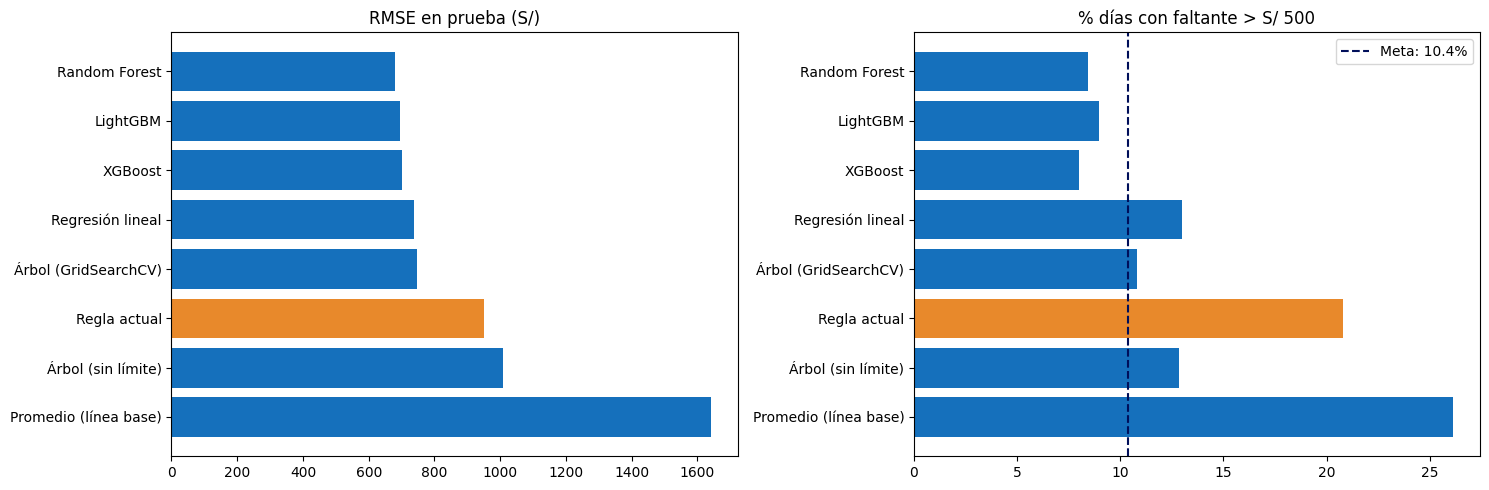

In [100]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
orden = tabla.sort_values("RMSE").index
colores = [NARANJA if n == NOMBRE_LINEA_BASE else AZUL for n in orden]
axes[0].barh(orden, tabla.loc[orden, "RMSE"], color=colores)
axes[0].invert_yaxis()
axes[0].set_title(f"RMSE en prueba ({UNIDAD})")
axes[1].barh(orden, tabla.loc[orden, IND], color=colores)
axes[1].invert_yaxis()
axes[1].axvline(META, color=MARINO, ls="--", label=f"Meta: {META:.1f}%")
axes[1].set_title(IND)
axes[1].legend()
plt.tight_layout()
plt.show()

Elegimos el modelo con **menor RMSE en prueba, porque los faltantes grandes son los más costosos: el RMSE castiga más los errores grandes**.

In [101]:
candidatos_ml = tabla.drop(index=[NOMBRE_LINEA_BASE, "Promedio (línea base)"])
MEJOR = candidatos_ml["RMSE"].idxmin()
mejor_modelo = modelos[MEJOR]
mejor = predicciones[MEJOR]
print("Modelo seleccionado:", MEJOR)
pd.DataFrame({NOMBRE_LINEA_BASE: tabla.loc[NOMBRE_LINEA_BASE, ["MAE", "RMSE", "MAPE (%)", "R²", IND]],
              MEJOR: tabla.loc[MEJOR, ["MAE", "RMSE", "MAPE (%)", "R²", IND]]}).round(2)

Modelo seleccionado: Random Forest


,Regla actual,Random Forest
MAE,573.51,344.19
RMSE,952.25,680.27
MAPE (%),34.75,16.81
R²,0.66,0.83
% días con faltante > S/ 500,20.78,8.45


### Entrenamiento vs. prueba: ¿hay sobreajuste?

,R² train,R² test,Diferencia
Random Forest,0.89,0.83,0.07
LightGBM,0.91,0.82,0.09
XGBoost,0.91,0.82,0.09
Regresión lineal,0.80,0.80,-0.00
Árbol (GridSearchCV),0.86,0.79,0.06
Árbol (sin límite),1.00,0.62,0.38


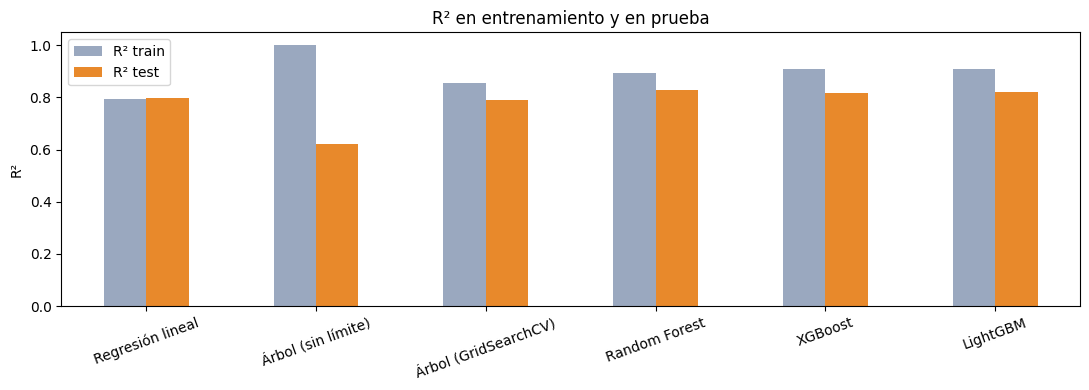

In [102]:
resumen = tabla.drop(index=[NOMBRE_LINEA_BASE, "Promedio (línea base)"])[["R² train", "R²"]].rename(columns={"R²": "R² test"})
resumen["Diferencia"] = resumen["R² train"] - resumen["R² test"]
display(resumen.sort_values("R² test", ascending=False))

resumen[["R² train", "R² test"]].plot.bar(figsize=(11, 4), color=[GRIS, NARANJA], rot=20)
plt.ylabel("R²")
plt.title("R² en entrenamiento y en prueba")
plt.tight_layout()
plt.show()

**Respuesta:** los modelos de ensamble son los mejores. **Random Forest** tiene el menor RMSE (S/ 680) y un MAE de S/ 344, casi empatado con LightGBM y XGBoost. Frente a la regla, el error promedio baja 40% (de S/ 574 a S/ 344) y el R² sube de 0.66 a 0.83.

- **Sobreajuste:** el árbol sin límite memoriza (R² train = 1.00 y test = 0.62). Random Forest tiene una brecha pequeña (0.89 frente a 0.83), aceptable.
- La regresión lineal tiene un R² parecido (0.80), pero un MAPE de 29%: se equivoca mucho en agentes pequeños porque no capta el efecto multiplicativo del día y de la zona.

## 8. Pregunta 5 · Importancia de variables

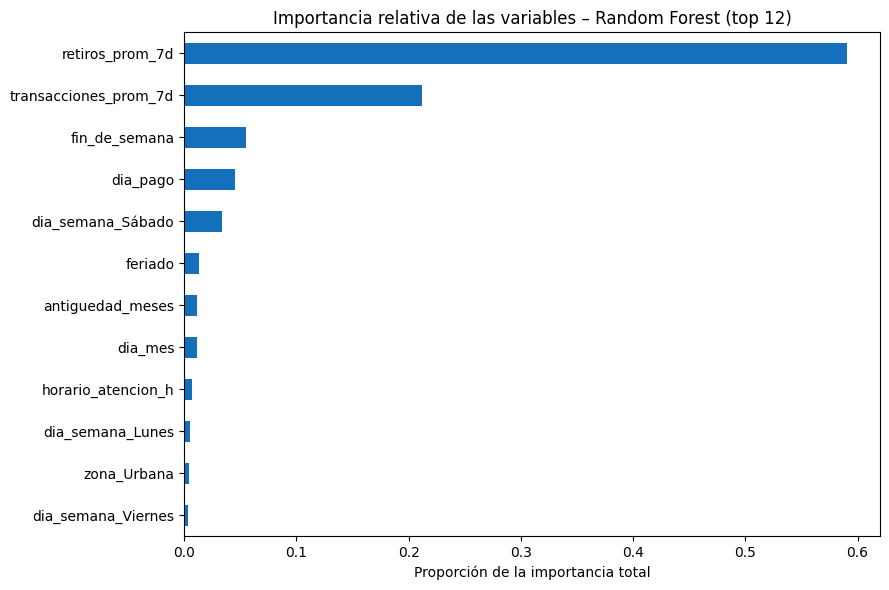

Top 3 variables:
retiros_prom_7d         0.59
transacciones_prom_7d   0.21
fin_de_semana           0.06
dtype: float64


In [103]:
def importancia(modelo):
    if isinstance(modelo, lgb.LGBMRegressor):
        valores = modelo.booster_.feature_importance(importance_type="gain")
    elif isinstance(modelo, LinearRegression):
        valores = np.abs(modelo.coef_) * X_train.std().values   # efecto de una desviación estándar
    else:
        valores = modelo.feature_importances_
    s = pd.Series(valores, index=X.columns)
    return s / s.sum()

imp = importancia(mejor_modelo).sort_values()
imp.tail(12).plot.barh(figsize=(9, 6), color=AZUL)
plt.title(f"Importancia relativa de las variables – {MEJOR} (top 12)")
plt.xlabel("Proporción de la importancia total")
plt.tight_layout()
plt.show()
print("Top 3 variables:")
print(imp.sort_values(ascending=False).head(3).round(3))

**Las tres variables más influyentes** son `retiros_prom_7d` (59%), `transacciones_prom_7d` (21%) y `fin_de_semana` (6%). Las dos primeras definen el **tamaño del agente**; luego el modelo ajusta según el **calendario**: fin de semana, día de la semana y día de pago. Esa información es justamente la que la regla actual ignora.

## 9. Pregunta 4 (continuación) · ¿Dónde se equivoca el modelo?

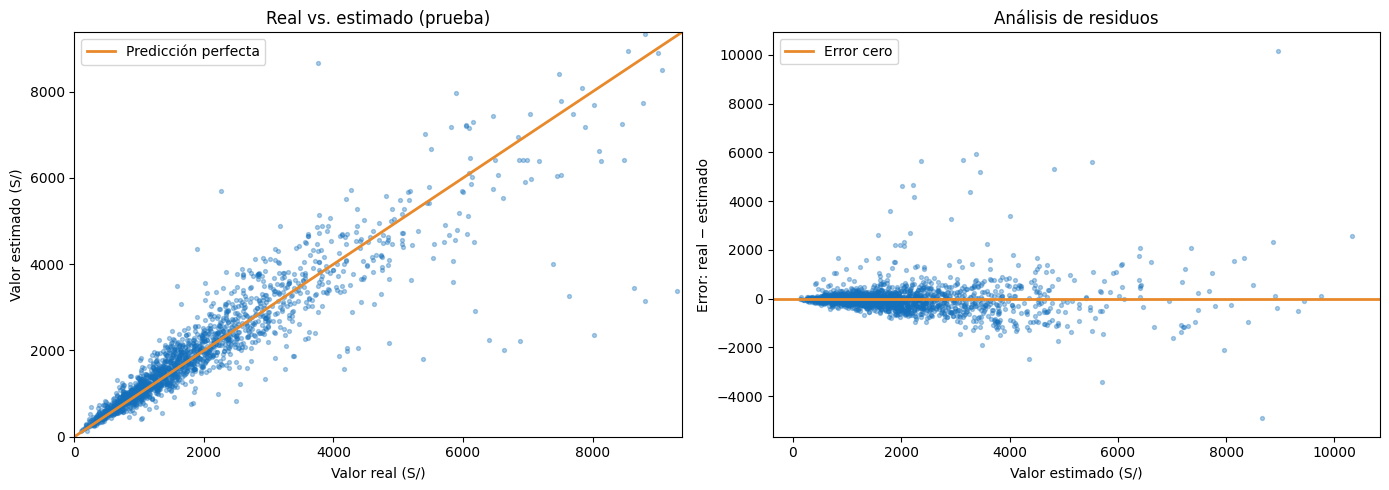

In [104]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
lim = [0, float(np.percentile(y_test, 99.5))]
axes[0].scatter(y_test, mejor, s=8, alpha=0.35, color=AZUL)
axes[0].plot(lim, lim, color=NARANJA, lw=2, label="Predicción perfecta")
axes[0].set_xlim(lim); axes[0].set_ylim(lim)
axes[0].set_xlabel(f"Valor real ({UNIDAD})")
axes[0].set_ylabel(f"Valor estimado ({UNIDAD})")
axes[0].set_title("Real vs. estimado (prueba)")
axes[0].legend()
axes[1].scatter(mejor, y_test - mejor, s=8, alpha=0.35, color=AZUL)
axes[1].axhline(0, color=NARANJA, lw=2, label="Error cero")
axes[1].set_xlabel(f"Valor estimado ({UNIDAD})")
axes[1].set_ylabel("Error: real − estimado")
axes[1].set_title("Análisis de residuos")
axes[1].legend()
plt.tight_layout()
plt.show()

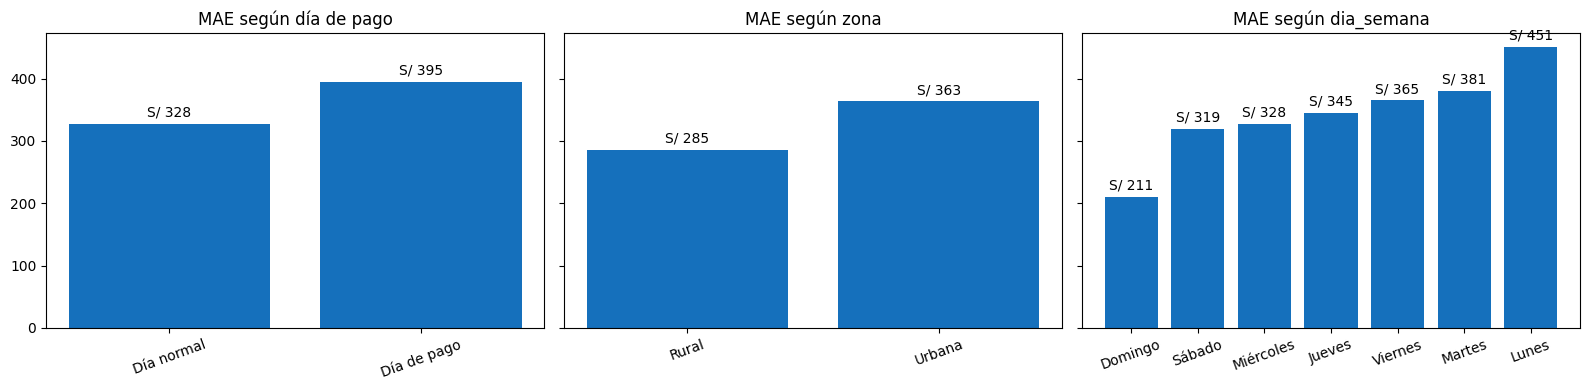

In [105]:
segmentos = datos.loc[X_test.index].assign(error_abs=np.abs(y_test - mejor))
segmentos["Día de pago"] = np.where(segmentos["dia_pago"] == 1, "Día de pago", "Día normal")
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, col in zip(axes, ["Día de pago", "zona", "dia_semana"]):
    mae_seg = segmentos.groupby(col)["error_abs"].mean().sort_values()
    barras = ax.bar(mae_seg.index.astype(str), mae_seg.values, color=AZUL)
    ax.bar_label(barras, fmt="S/ %.0f", padding=3)
    ax.set_title(f"MAE según {col.lower()}")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

**Respuesta:** la mayoría de errores está cerca de cero, pero hay días muy por encima de la diagonal: son los eventos atípicos de retiros, que ningún modelo puede anticipar con estos datos. El error es mayor en **días de pago** (S/ 395 frente a S/ 328), en la **zona urbana** (agentes más grandes) y los **lunes**, que son los días con más retiros.

## 10. Pregunta 6 · Predicción para los nuevos registros

Reentrenamos el modelo seleccionado con **todos** los datos y aplicamos la misma preparación (limpieza, variables derivadas y dummies) al archivo nuevo.

In [106]:
modelo_final = modelos[MEJOR].__class__(**modelos[MEJOR].get_params())
modelo_final.fit(X, y)

nuevos = pd.read_csv(ARCHIVO_NUEVOS)
nuevos_prep = crear_variables(limpiar(nuevos, es_nuevo=True))
X_nuevos = pd.get_dummies(nuevos_prep.drop(columns=COLUMNAS_A_EXCLUIR, errors="ignore"),
                          columns=CATEGORICAS, dtype=int).reindex(columns=X.columns, fill_value=0)

nuevos[f"{OBJETIVO}_estimado"] = modelo_final.predict(X_nuevos).round(0)
nuevos[[ID, f"{OBJETIVO}_estimado"]].to_csv(SALIDA_NUEVOS, index=False)
print(f"Archivo exportado: {SALIDA_NUEVOS} ({len(nuevos)} registros)")
nuevos[[ID, f"{OBJETIVO}_estimado"]].head(10)

Archivo exportado: PD_prediccion_agentes.csv (25 registros)


,id_registro,monto_retiros_estimado
0,900001,1519.00
1,900002,2162.00
2,900003,2136.00
3,900004,2832.00
4,900005,2840.00
5,900006,3787.00
6,900007,1271.00
7,900008,2859.00
8,900009,2010.00
9,900010,3563.00


In [107]:
print("Resumen de las estimaciones:")
nuevos[f"{OBJETIVO}_estimado"].describe().round(0)

Resumen de las estimaciones:


,monto_retiros_estimado
count,25.00
mean,2722.00
std,1526.00
min,877.00
25%,1519.00
50%,2541.00
75%,3399.00
max,6592.00


**Respuesta:** se exporta `PD_prediccion_agentes.csv` con el efectivo estimado para los 25 agentes nuevos (1 de octubre de 2026, día de pago). Las estimaciones van de unos S/ 900 a S/ 6,600, con una mediana de S/ 2,541.

## 11. Pregunta 7 · Del error del modelo a la decisión

In [108]:
ind_modelo = indicador(y_test, mejor)
casos_base = round(CASOS_POR_MES * ind_regla / 100)
casos_modelo = round(CASOS_POR_MES * ind_modelo / 100)
ahorro_mes = (casos_base - casos_modelo) * COSTO_POR_CASO

pd.DataFrame({
    "Error promedio (MAE)": [f"{tabla.loc[NOMBRE_LINEA_BASE, 'MAE']:,.0f} {UNIDAD}", f"{tabla.loc[MEJOR, 'MAE']:,.0f} {UNIDAD}"],
    IND: [f"{ind_regla:.1f}%", f"{ind_modelo:.1f}%"],
    f"Meta (≤ {META:.1f}%)": ["Cumple" if p <= META else "No cumple" for p in (ind_regla, ind_modelo)],
    f"{NOMBRE_COSTO.capitalize()} al mes": [f"{casos_base:,}", f"{casos_modelo:,}"],
    "Costo al mes": [f"S/ {casos_base * COSTO_POR_CASO:,.0f}", f"S/ {casos_modelo * COSTO_POR_CASO:,.0f}"],
}, index=[NOMBRE_LINEA_BASE, MEJOR])

,Error promedio (MAE),% días con faltante > S/ 500,Meta (≤ 10.4%),Faltantes al mes,Costo al mes
Regla actual,574 S/,20.8%,No cumple,"5,610","S/ 224,400"
Random Forest,344 S/,8.4%,Cumple,"2,280","S/ 91,200"


In [109]:
print(f"Ahorro estimado: S/ {ahorro_mes:,.0f} al mes, unos S/ {ahorro_mes * 12:,.0f} al año.")

Ahorro estimado: S/ 133,200 al mes, unos S/ 1,598,400 al año.


**Recomendación:** abastecer a cada agente con la estimación del modelo en lugar del promedio de 7 días. Los días con faltante bajan de **20.8% a 8.4%**, por debajo de la meta de 10.4%, con un ahorro estimado de **S/ 133 mil al mes**. En los días de pago y en los agentes rurales conviene, además, añadir un margen de seguridad, porque es donde el error es mayor.

# Caso 2 – Predicción de transacciones diarias de recaudación

Una empresa del sector de recaudación de pagos (servicios, telefonía móvil y otros) busca anticipar el número de transacciones diarias para mejorar la planificación operativa. La base `PD_recaudos_trx.csv` registra las transacciones diarias. Se sigue el mismo esquema del Caso 2 visto en clase.

## 1. Librerías y carga de datos

In [110]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import timedelta

from xgboost import XGBRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    mean_absolute_percentage_error,
    r2_score
)

In [111]:
file_path = 'PD_recaudos_trx.csv'
df = pd.read_csv(file_path)
df['fecha'] = pd.to_datetime(df['fecha'])
df.tail()

,fecha,cant_trx
648,2025-10-10,78420
649,2025-10-11,64342
650,2025-10-12,45892
651,2025-10-13,90889
652,2025-10-14,80558


In [112]:
print(df.isnull().sum())
df.describe()

fecha       0
cant_trx    0
dtype: int64


,fecha,cant_trx
count,653,653.00
mean,2024-11-22 00:00:00,70459.11
min,2024-01-01 00:00:00,12889.00
25%,2024-06-12 00:00:00,62546.00
50%,2024-11-22 00:00:00,72852.00
75%,2025-05-04 00:00:00,80923.00
max,2025-10-14 00:00:00,110652.00
std,NaN,16716.91


## 2. Pregunta 1 · Gráfico de la serie temporal

In [113]:
print('Inicio del registro histórico:', df['fecha'].min().date())
print('Último registro disponible:  ', df['fecha'].max().date())
print('Número de días registrados:  ', len(df))

Inicio del registro histórico: 2024-01-01
Último registro disponible:   2025-10-14
Número de días registrados:   653


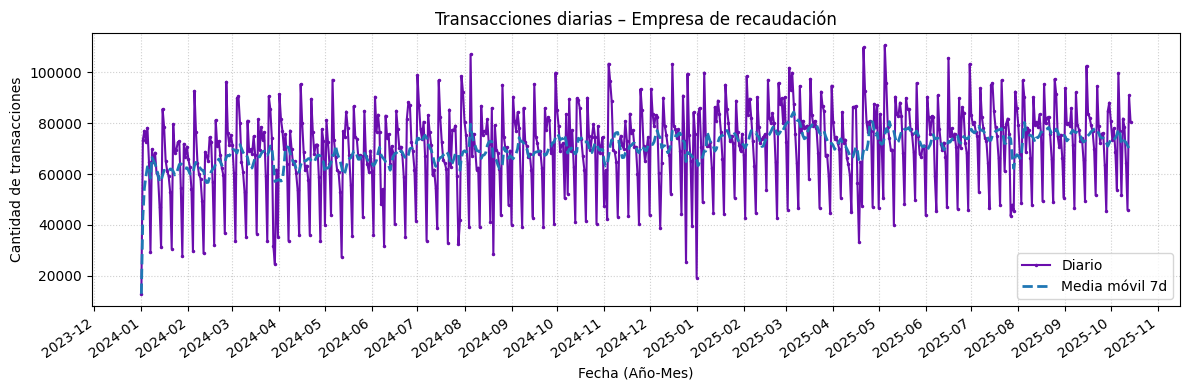

In [114]:
dfp = df.sort_values('fecha').copy()
dfp['mm7'] = dfp['cant_trx'].rolling(7, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(dfp['fecha'], dfp['cant_trx'], label='Diario', linewidth=1.5, marker='.', ms=3, color='#6A0DAD')
ax.plot(dfp['fecha'], dfp['mm7'], label='Media móvil 7d', linewidth=2, linestyle='--')
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.xticks(rotation=35, ha='right')
ax.set_title('Transacciones diarias – Empresa de recaudación')
ax.set_xlabel('Fecha (Año-Mes)')
ax.set_ylabel('Cantidad de transacciones')
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend()
plt.tight_layout()
plt.show()

In [115]:
mensual = (df.set_index('fecha')['cant_trx']
             .resample('MS').agg(['sum', 'count'])
             .rename(columns={'sum': 'transacciones', 'count': 'dias_con_dato'}))
mensual['var_%'] = (mensual['transacciones'].pct_change() * 100).round(1)
mensual

,transacciones,dias_con_dato,var_%
fecha,,,
2024-01-01,1897496,31,NaN
2024-02-01,1849114,29,-2.50
2024-03-01,1982007,31,7.20
2024-04-01,2002149,30,1.00
2024-05-01,2038967,31,1.80
2024-06-01,2001694,30,-1.80
2024-07-01,2147598,31,7.30
2024-08-01,2116516,31,-1.40
2024-09-01,2106830,30,-0.50


**Respuesta a la Pregunta 1:** el registro inicia el **1 de enero de 2024** y llega hasta el 14 de octubre de 2025 (653 días). La tendencia es **levemente creciente y estable**: el total mensual pasa de 1.9 millones (enero 2024) a 2.2–2.4 millones en 2025, alrededor de +8% interanual. Hay una estacionalidad semanal muy marcada: los lunes son los días de mayor volumen y los domingos los de menor; los feriados caen fuertemente.

## 3. Preparación de datos e ingeniería de variables

In [116]:
data = df.rename(columns={'fecha': 'Fecha', 'cant_trx': 'Valor'}).sort_values('Fecha')
DIAS = ['Lunes', 'Martes', 'Miércoles', 'Jueves', 'Viernes', 'Sábado', 'Domingo']

feriados = pd.to_datetime([
    '2024-01-01', '2024-03-28', '2024-03-29', '2024-05-01',
    '2024-06-29', '2024-07-23', '2024-07-28', '2024-07-29', '2024-08-30',
    '2024-10-08', '2024-11-01', '2024-12-08', '2024-12-25', '2024-12-31',
    '2025-01-01', '2025-04-17', '2025-04-18', '2025-05-01',
    '2025-06-29', '2025-07-28', '2025-07-29', '2025-08-30',
    '2025-10-08', '2025-11-01', '2025-12-08', '2025-12-25', '2025-12-31',
    '2026-01-01', '2026-04-02', '2026-04-03', '2026-05-01',
    '2026-06-29', '2026-07-28', '2026-07-29', '2026-08-30',
    '2026-10-08', '2026-11-01', '2026-12-08', '2026-12-25', '2026-12-31',
    '2027-01-01'
])

In [117]:
serie = data.set_index('Fecha').asfreq('D')
serie['Valor'] = serie['Valor'].ffill()

df_feat = serie.copy()
df_feat['dayofweek'] = df_feat.index.dayofweek
df_feat['day'] = df_feat.index.day
df_feat['week'] = df_feat.index.isocalendar().week.astype(int)
df_feat['month'] = df_feat.index.month
df_feat['year'] = df_feat.index.year
df_feat['is_weekend'] = (df_feat['dayofweek'] >= 5).astype(int)
df_feat['is_holiday'] = df_feat.index.isin(feriados).astype(int)
df_feat['rolling_7'] = df_feat['Valor'].rolling(window=7).mean()
for lag in [1, 7, 14]:
    df_feat[f'lag_{lag}'] = df_feat['Valor'].shift(lag)
df_feat = df_feat.dropna()
df_feat.head()

,Valor,dayofweek,day,week,month,year,is_weekend,is_holiday,rolling_7,lag_1,lag_7,lag_14
Fecha,,,,,,,,,,,,
2024-01-15,85594,0,15,3,1,2024,0,0,59522.00,31233.00,69721.00,12889.00
2024-01-16,78442,1,16,3,1,2024,0,0,61494.14,85594.00,64637.00,73435.00
2024-01-17,65269,2,17,3,1,2024,0,0,61044.14,78442.00,68419.00,77030.00
2024-01-18,61364,3,18,3,1,2024,0,0,61185.14,65269.00,60377.00,72748.00
2024-01-19,59060,4,19,3,1,2024,0,0,61156.86,61364.00,59258.00,78184.00


## 4. Pregunta 2 · Modelado con dos algoritmos de ML

Reservamos los últimos 21 días como *holdout* y los pronosticamos de forma **recursiva**: cada predicción alimenta los lags del día siguiente.

In [118]:
def mape(y_true, y_pred, eps=1e-8):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    denom = np.where(np.abs(y_true) < eps, eps, np.abs(y_true))
    return np.mean(np.abs((y_true - y_pred) / denom)) * 100


def resumen_metricas(y_true, y_pred):
    return pd.DataFrame([{
        'n_obs': len(y_true),
        'MAE': mean_absolute_error(y_true, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
        'MAPE_%': mean_absolute_percentage_error(y_true, y_pred) * 100,
        'R2': r2_score(y_true, y_pred)
    }])


def pronostico_recursivo(modelo, historial, fechas):
    last_known = historial.copy()
    preds = []
    for date in fechas:
        row = {
            'dayofweek': date.dayofweek,
            'day': date.day,
            'week': int(date.isocalendar().week),
            'month': date.month,
            'year': date.year,
            'is_weekend': int(date.dayofweek >= 5),
            'is_holiday': int(date in feriados),
            'rolling_7': last_known['Valor'].iloc[-7:].mean(),
            'lag_1': last_known['Valor'].iloc[-1],
            'lag_7': last_known['Valor'].iloc[-7],
            'lag_14': last_known['Valor'].iloc[-14],
        }
        X_pred = pd.DataFrame([row], index=[date])
        y_pred = modelo.predict(X_pred)[0]
        preds.append(y_pred)
        last_known.loc[date] = row
        last_known.loc[date, 'Valor'] = y_pred
    return pd.Series(preds, index=fechas, name='pred')

In [119]:
holdout_days = 21
X_all = df_feat.drop(columns='Valor')
y_all = df_feat['Valor']
X_train, y_train = X_all.iloc[:-holdout_days], y_all.iloc[:-holdout_days]
test_dates = df_feat.index[-holdout_days:]
print('Entrenamiento:', X_train.index.min().date(), 'a', X_train.index.max().date())
print('Holdout:      ', test_dates.min().date(), 'a', test_dates.max().date())

model_xgb = XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=4, random_state=42, verbosity=0)
model_xgb.fit(X_train, y_train)
pred_xgb = pronostico_recursivo(model_xgb, df_feat.iloc[:-holdout_days], test_dates)

model_rf = RandomForestRegressor(n_estimators=100, random_state=42)
model_rf.fit(X_train, y_train)
pred_rf = pronostico_recursivo(model_rf, df_feat.iloc[:-holdout_days], test_dates)

Entrenamiento: 2024-01-15 a 2025-09-23
Holdout:       2025-09-24 a 2025-10-14


In [120]:
y_true = y_all.loc[test_dates]
resultados = pd.concat([
    resumen_metricas(y_true, pred_xgb).assign(Modelo='XGBoost'),
    resumen_metricas(y_true, pred_rf).assign(Modelo='Random Forest')
]).set_index('Modelo').round(3)

mejor_modelo = resultados['MAPE_%'].idxmin()
model_final = model_xgb if mejor_modelo == 'XGBoost' else model_rf
pred_final = pred_xgb if mejor_modelo == 'XGBoost' else pred_rf
print('Modelo seleccionado (menor MAPE):', mejor_modelo)
resultados

Modelo seleccionado (menor MAPE): XGBoost


,n_obs,MAE,RMSE,MAPE_%,R2
Modelo,,,,,
XGBoost,21,3833.91,4581.08,5.31,0.89
Random Forest,21,4117.61,4918.71,5.90,0.88


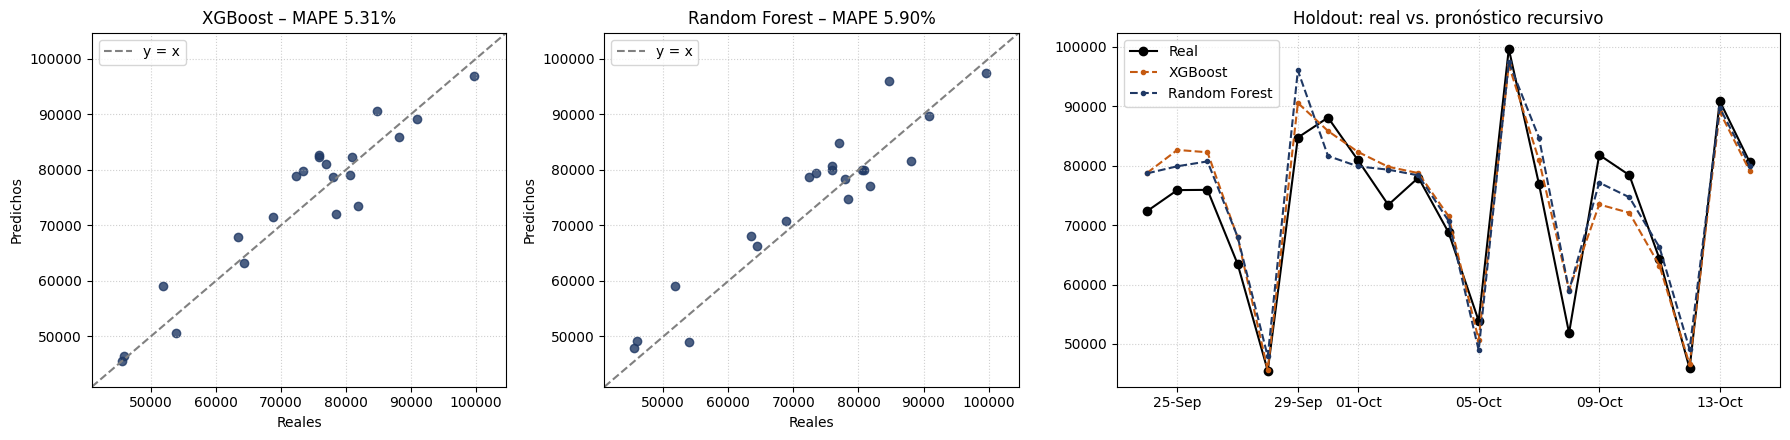

In [121]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), gridspec_kw={'width_ratios': [1, 1, 1.6]})
for ax, (nombre, pred) in zip(axes[:2], [('XGBoost', pred_xgb), ('Random Forest', pred_rf)]):
    ax.scatter(y_true, pred, color='#1F3864', alpha=0.8)
    lim = [min(y_true.min(), pred.min()) * 0.9, max(y_true.max(), pred.max()) * 1.05]
    ax.plot(lim, lim, linestyle='--', color='grey', label='y = x')
    ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_title(f'{nombre} – MAPE {resultados.loc[nombre, "MAPE_%"]:.2f}%')
    ax.set_xlabel('Reales'); ax.set_ylabel('Predichos')
    ax.grid(True, linestyle=':', alpha=0.6); ax.legend()
axes[2].plot(y_true.index, y_true, color='black', marker='o', label='Real')
axes[2].plot(pred_xgb.index, pred_xgb, color='#C55A11', linestyle='--', marker='.', label='XGBoost')
axes[2].plot(pred_rf.index, pred_rf, color='#1F3864', linestyle='--', marker='.', label='Random Forest')
axes[2].xaxis.set_major_formatter(mdates.DateFormatter('%d-%b'))
axes[2].set_title('Holdout: real vs. pronóstico recursivo')
axes[2].grid(True, linestyle=':', alpha=0.6); axes[2].legend()
plt.tight_layout()
plt.show()

**Respuesta a la Pregunta 2:** **XGBoost** es el mejor modelo en todas las métricas: MAPE de 5.3% frente a 5.9% de Random Forest, MAE de 3,834 frente a 4,118 transacciones diarias y R² de 0.89 frente a 0.88. Los puntos del gráfico de dispersión están cerca de la diagonal y el pronóstico recursivo sigue bien el patrón semanal; los mayores errores están en los picos de los lunes.

## 5. Pregunta 3 · Importancia de variables

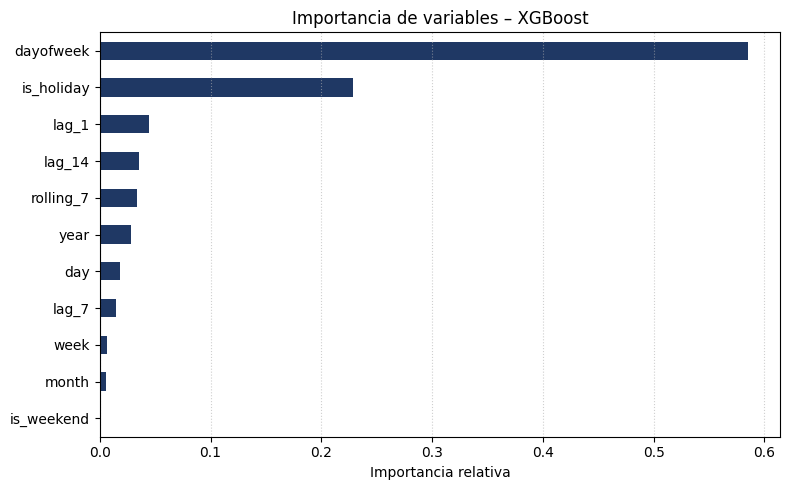

,0
dayofweek,0.58
is_holiday,0.23
lag_1,0.04
lag_14,0.04
rolling_7,0.03
year,0.03
day,0.02
lag_7,0.01
week,0.01
month,0.00


In [122]:
importancia = pd.Series(model_final.feature_importances_, index=X_train.columns).sort_values()
importancia.plot(kind='barh', figsize=(8, 5), color='#1F3864')
plt.title(f'Importancia de variables – {mejor_modelo}')
plt.xlabel('Importancia relativa')
plt.grid(True, axis='x', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()
importancia.sort_values(ascending=False).round(3)

**Respuesta a la Pregunta 3:** `dayofweek` (58%) e `is_holiday` (23%) explican la mayor parte del pronóstico: en esta serie el **calendario** pesa más que la historia reciente. Los lags y la media móvil (3–4% cada uno) solo ajustan el nivel. Es coherente con una serie estable, donde el volumen depende sobre todo de qué día es.

## 6. Pregunta 4 · Predicciones diarias y de los tres meses siguientes

In [123]:
future_dates = pd.date_range(start=serie.index.max() + timedelta(days=1), end='2026-01-31', freq='D')
predictions = pronostico_recursivo(model_final, df_feat, future_dates)
forecast = pd.DataFrame({'Fecha': future_dates, 'Valor': np.clip(predictions.values, 0, None)})
print('Horizonte:', future_dates.min().date(), 'a', future_dates.max().date(), f'({len(future_dates)} días)')

Horizonte: 2025-10-15 a 2026-01-31 (109 días)


In [124]:
periodo = forecast[(forecast['Fecha'] >= '2025-10-20') & (forecast['Fecha'] <= '2025-11-03')].copy()
periodo['Dia'] = [DIAS[d] for d in periodo['Fecha'].dt.dayofweek]
periodo['Valor'] = periodo['Valor'].round(0).astype(int)
periodo[['Fecha', 'Valor']].rename(columns={'Valor': 'Valor pronosticado'}).to_csv('PD_prediccion_recaudos.csv', index=False)
print('Total del periodo:', f"{periodo['Valor'].sum():,}")
periodo[['Fecha', 'Dia', 'Valor']].reset_index(drop=True)

Total del periodo: 1,119,501


,Fecha,Dia,Valor
0,2025-10-20,Lunes,94539
1,2025-10-21,Martes,82524
2,2025-10-22,Miércoles,76755
3,2025-10-23,Jueves,74577
4,2025-10-24,Viernes,73807
5,2025-10-25,Sábado,71937
6,2025-10-26,Domingo,51690
7,2025-10-27,Lunes,88831
8,2025-10-28,Martes,77739
9,2025-10-29,Miércoles,72859


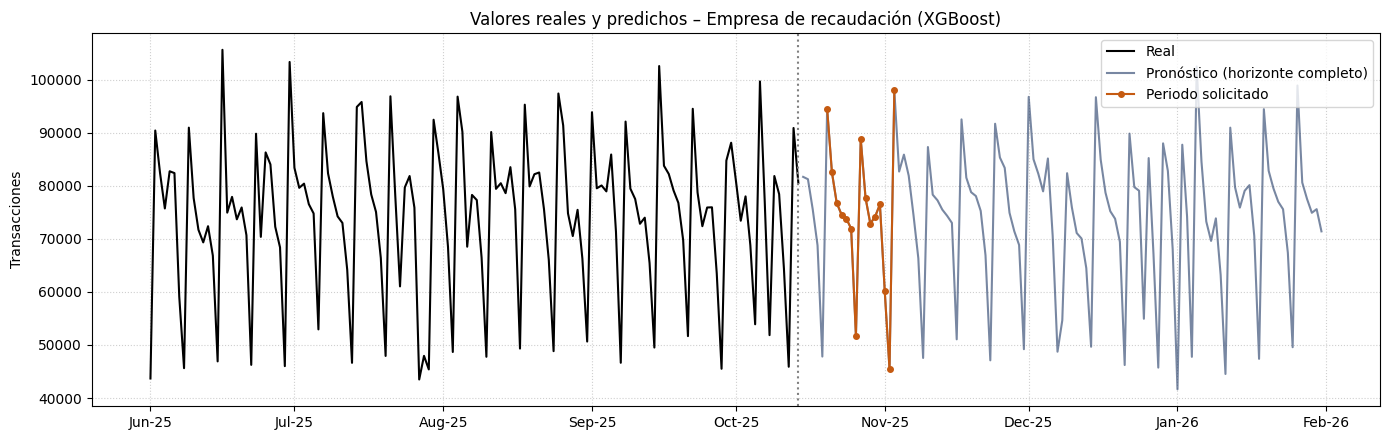

In [125]:
fig, ax = plt.subplots(figsize=(14, 4.5))
hist = serie[serie.index >= '2025-06-01']
ax.plot(hist.index, hist['Valor'], color='black', label='Real')
ax.plot(forecast['Fecha'], forecast['Valor'], color='#1F3864', alpha=0.6, label='Pronóstico (horizonte completo)')
ax.plot(periodo['Fecha'], periodo['Valor'], color='#C55A11', marker='o', ms=4, label='Periodo solicitado')
ax.axvline(serie.index.max(), color='grey', linestyle=':')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b-%y'))
ax.set_title(f'Valores reales y predichos – Empresa de recaudación ({mejor_modelo})')
ax.set_ylabel('Transacciones')
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend()
plt.tight_layout()
plt.show()

In [126]:
forecast['Mes'] = forecast['Fecha'].dt.to_period('M')
pred_mensual = forecast.groupby('Mes')['Valor'].sum().round(0).astype(int)
pred_mensual = pred_mensual.loc[['2025-11', '2025-12', '2026-01']].to_frame('Prediccion')
real_mensual = mensual[mensual['dias_con_dato'] == mensual.index.days_in_month]['transacciones']
real_mensual.index = real_mensual.index.to_period('M')
pred_mensual['Real_anio_anterior'] = [real_mensual.get(m - 12, np.nan) for m in pred_mensual.index]
pred_mensual['Var_vs_anio_anterior_%'] = ((pred_mensual['Prediccion'] / pred_mensual['Real_anio_anterior'] - 1) * 100).round(1)
pred_mensual['Var_vs_ultimo_mes_%'] = ((pred_mensual['Prediccion'] / real_mensual.iloc[-1] - 1) * 100).round(1)
print('Último mes completo:', real_mensual.index[-1], f"({real_mensual.iloc[-1]:,})")
pred_mensual

Último mes completo: 2025-09 (2,272,235)


,Prediccion,Real_anio_anterior,Var_vs_anio_anterior_%,Var_vs_ultimo_mes_%
Mes,,,,
2025-11,2203996,2109749,4.50,-3.00
2025-12,2281092,2217094,2.90,0.40
2026-01,2291617,2244487,2.10,0.90


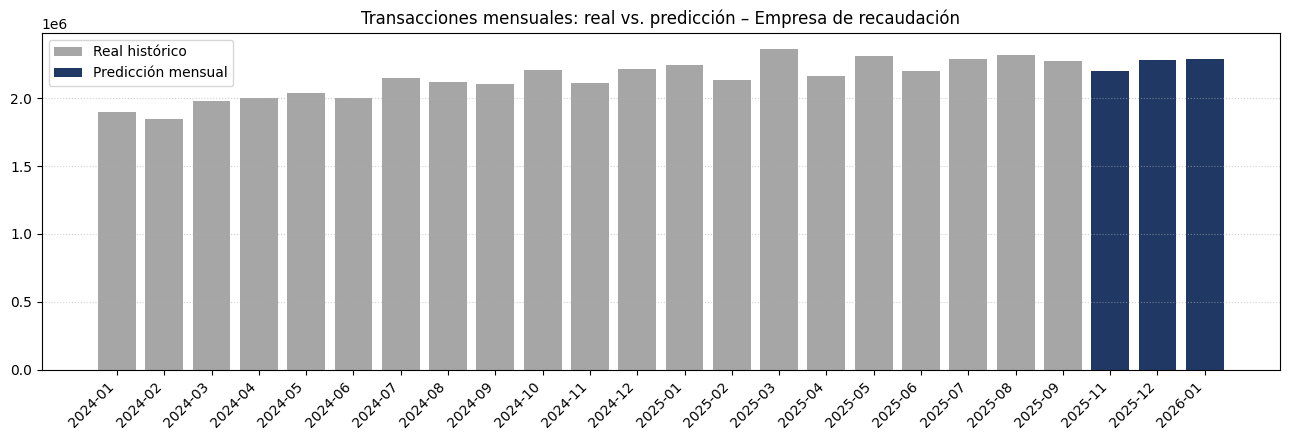

In [127]:
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.bar(real_mensual.index.astype(str), real_mensual.values, color='#A6A6A6', label='Real histórico')
ax.bar(pred_mensual.index.astype(str), pred_mensual['Prediccion'], color='#1F3864', label='Predicción mensual')
plt.xticks(rotation=45, ha='right')
ax.set_title(f'Transacciones mensuales: real vs. predicción – Empresa de recaudación')
ax.grid(True, axis='y', linestyle=':', alpha=0.6)
ax.legend()
plt.tight_layout()
plt.show()

**Respuesta a la Pregunta 4:** del 20 de octubre al 3 de noviembre de 2025 se pronostican **1.12 millones** de transacciones. Los lunes llegan a 89–98 mil; el 1 de noviembre (feriado) baja a 60 mil y el domingo 2 a 45 mil. Por mes, se proyectan **2.20 millones en noviembre, 2.28 millones en diciembre y 2.29 millones en enero**, entre 2% y 5% por encima del mismo mes del año anterior. El resultado es **coherente con la tendencia** levemente creciente y estable de la serie.

## Resumen de respuestas

| Caso | Pregunta | Respuesta clave |
|---|---|---|
| 1 | Calidad | Nulos en antigüedad y horario (imputados con la mediana); antigüedad 999 = error; 120 días con agente cerrado eliminados |
| 1 | Hallazgos | Lunes +23% y domingo −51%; días de pago +61% en zona rural |
| 1 | Línea base | MAE S/ 574 · faltantes 20.8% |
| 1 | Mejor modelo | Random Forest: RMSE S/ 680 · MAE S/ 344 · R² 0.83 |
| 1 | Top 3 variables | retiros_prom_7d, transacciones_prom_7d, fin_de_semana |
| 1 | Decisión | Faltantes 20.8% → 8.4% (meta 10.4%) · ahorro S/ 133 mil al mes |
| 2 | Serie | Desde el 1-ene-2024; tendencia levemente creciente y estable |
| 2 | Mejor modelo | XGBoost: MAPE 5.3% |
| 2 | Variables | dayofweek e is_holiday |
| 2 | Pronóstico | 1.12 M (20-oct al 3-nov) · nov 2.20 M · dic 2.28 M · ene 2.29 M |